In [1]:
from neuromodes import mbm as mbm
from neuromodes.io import fetch_example_surf

In [2]:
from scipy.io import loadmat

In [3]:
from importlib.resources import files, as_file
from nsbutils.plotting import plot_surf
from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf

# Load cortical surface mesh
surf, medmask = fetch_example_surf()

# Initialise solver with surface
solver = EigenSolver(surf, mask=medmask).solve(200)

print(solver)


EigenSolver
-----------
Surface mesh: 29696 vertices (2796 others masked out), 59147 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 200 computed


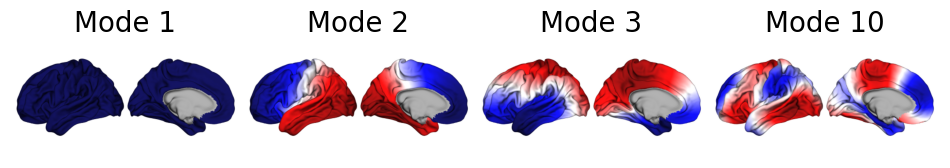

In [23]:
modes_unmasked = solver.unmask_data(solver.emodes)

lh_surfpath = files('neuromodes.data') / 'sp-human_tpl-fsLR_den-32k_hemi-L_midthickness.surf.gii'
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, modes_unmasked[:,[0,1,2,9]], labels=['Mode 1', 'Mode 2', 'Mode 3', 'Mode 10'], cmap='seismic')

In [40]:
import numpy as np
face = np.random.default_rng().normal(size=(solver.n_verts, 255))
hand = np.random.default_rng().normal(size=(solver.n_verts, 255)) + solver.emodes[:,[1]]*5
hand = face + solver.emodes[:,[1]]*5

import numpy as np
weights = np.linspace(0.5, 1.5, 255)


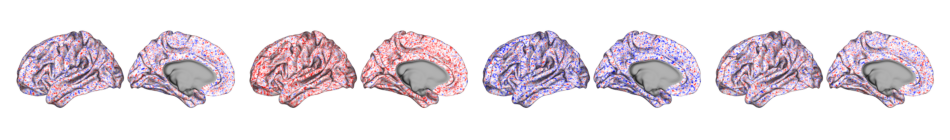

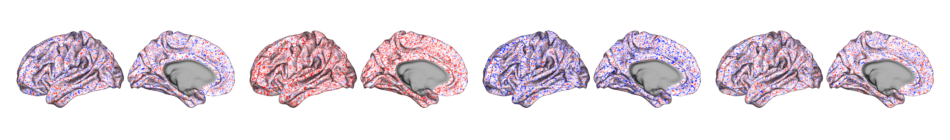

In [41]:
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(face[:,[0,1,2,9]]), cmap='seismic')
    plot_surf(lh_surfpath, solver.unmask_data(hand[:,[0,1,2,9]]), cmap='seismic')

In [70]:
import numpy as np

nsubj = 255

z = np.zeros((nsubj,1))
o = np.ones((nsubj,1))
response = np.vstack((face.T, hand.T))
statTest = 'ttest'

# design = np.vstack((np.hstack((o, np.eye(nsubj))), np.hstack((-o, np.eye(nsubj)))))
design = np.vstack((o, -o))

# contrast = np.hstack((np.array([[1,]]), np.zeros((1,nsubj))))
contrast = np.array([[1]])


# print(contrast)


In [71]:
statMap = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)

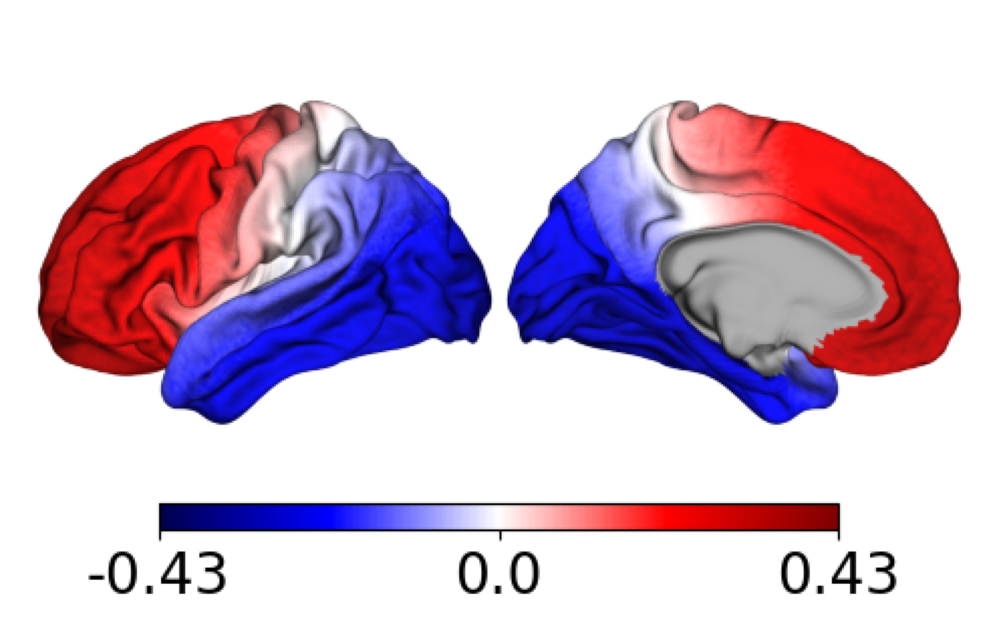

In [72]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(statMap), cmap='seismic', center=0, cbar=True, ax=axs)

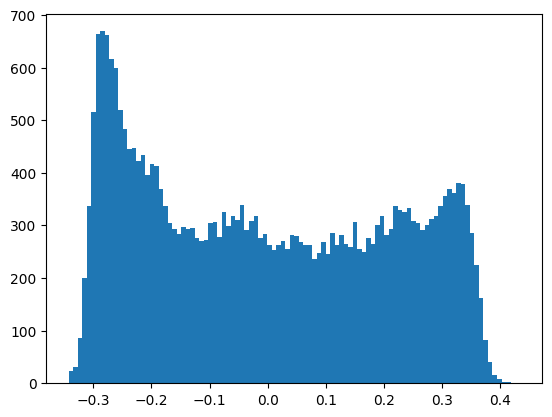

In [73]:


plt.hist(statMap, bins=100)
plt.show()

In [ ]:
permMap = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, n_permutations=10, permutationMethod='shuffle_rows')

In [75]:
pvals = mbm.mbm_calc_p_vals(statMap, permMap, 'two-sided', None)

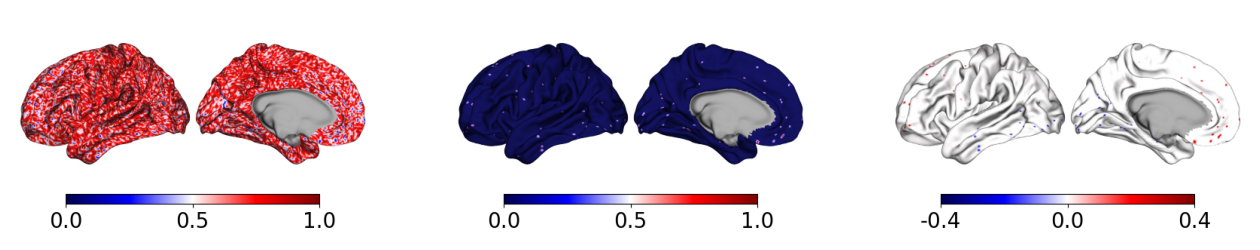

In [76]:
fig, axs = plt.subplots(1, 3, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(pvals), cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[0])
    plot_surf(lh_surfpath, solver.unmask_data(pvals<0.05), cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[1])
    plot_surf(lh_surfpath, solver.unmask_data((pvals<0.05)*statMap), cmap='seismic', center=0, cbar=True, ax=axs[2])

In [77]:
np.min(pvals), np.max(pvals)

(np.float64(0.0), np.float64(1.0))

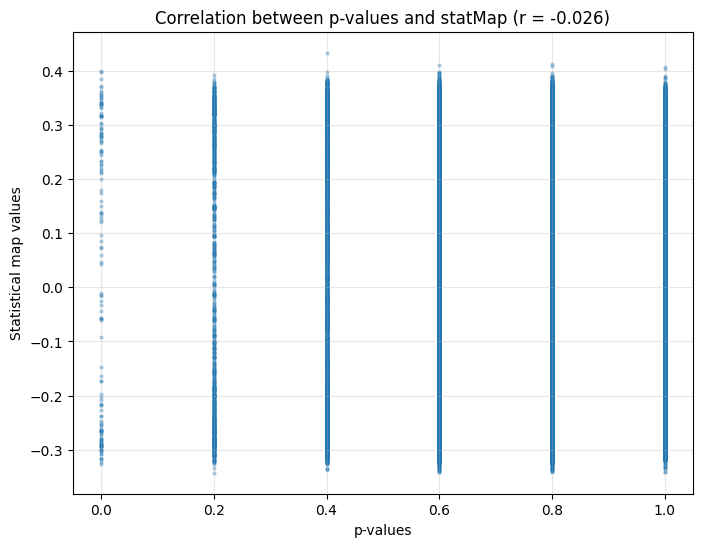

In [78]:
corr = np.corrcoef(pvals, statMap)[0, 1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pvals, statMap, s=4, alpha=0.3)
ax.set_xlabel('p-values')
ax.set_ylabel('Statistical map values')
ax.set_title(f'Correlation between p-values and statMap (r = {corr:.3f})')
ax.grid(alpha=0.3)

plt.show()

In [79]:
from neuromodes.basis import decompose
betas = decompose(statMap, solver.emodes, mass=solver.mass)
betaPerm = decompose(permMap, solver.emodes, mass=solver.mass)
betap = mbm.mbm_calc_p_vals(betas, betaPerm, 'two-sided', None)

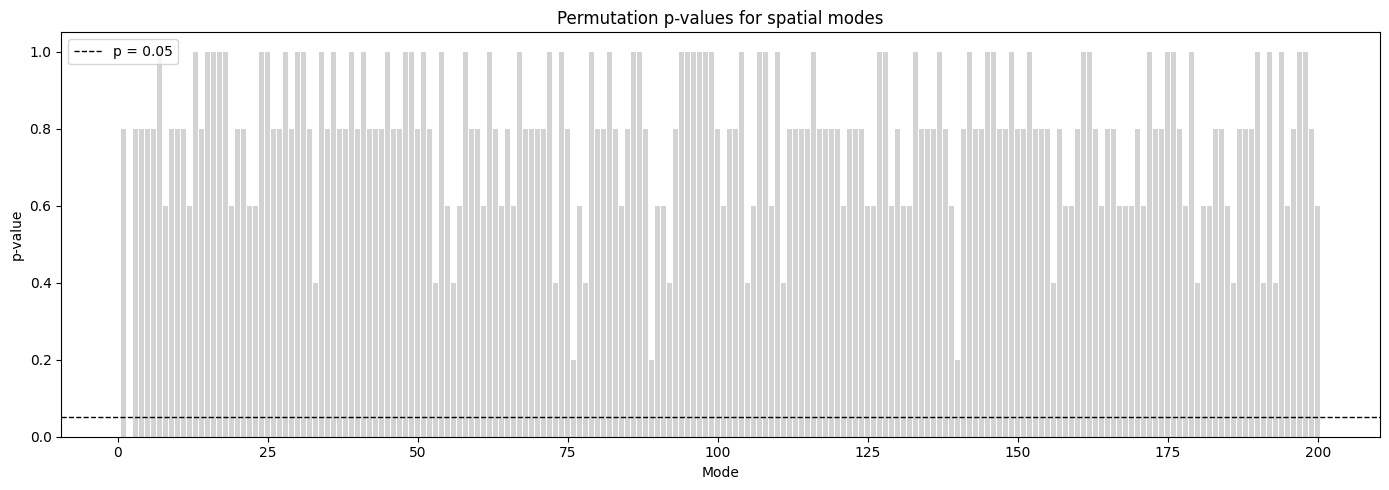

In [80]:
colors = np.where(betap < 0.05, 'crimson', 'lightgray')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(np.arange(len(betap)) + 1, betap, color=colors)
ax.axhline(0.05, color='black', linestyle='--', linewidth=1, label='p = 0.05')

ax.set_xlabel('Mode')
ax.set_ylabel('p-value')
ax.set_title('Permutation p-values for spatial modes')
ax.legend()
plt.tight_layout()
plt.show()

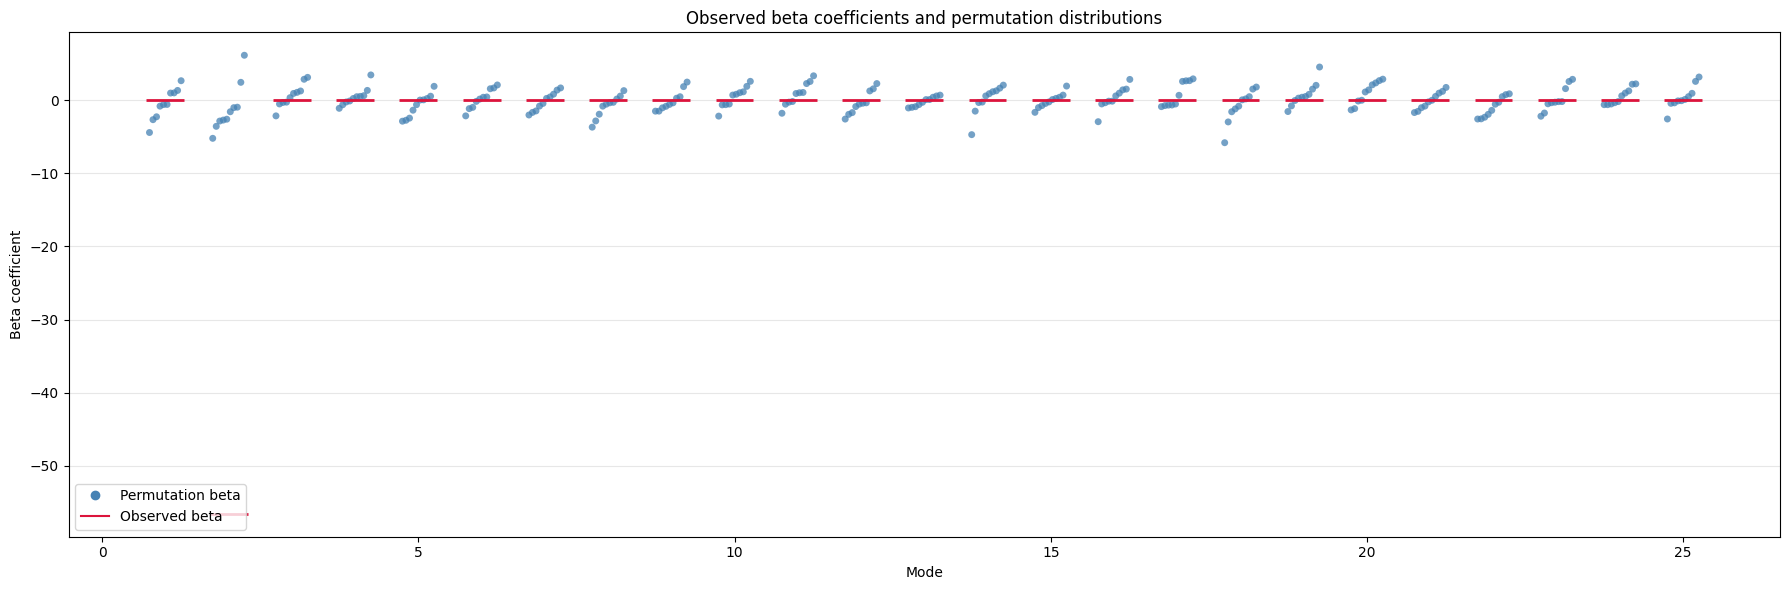

In [81]:
n_modes, n_permutations = betaPerm.shape
modes = np.arange(1, 25 + 1)

fig, ax = plt.subplots(figsize=(18, 6))

# Swarm-like horizontal offsets for permutation values
offsets = np.linspace(-0.25, 0.25, n_permutations)

for i, mode in enumerate(modes):
    values = np.sort(betaPerm[i, :])
    ax.scatter(
        mode + offsets,
        values,
        color='steelblue',
        alpha=0.75,
        s=25,
        edgecolor='none'
    )

    # Corresponding observed beta
    ax.hlines(
        betas[i],
        mode - 0.3,
        mode + 0.3,
        color='crimson',
        linewidth=2
    )

ax.set_xlabel('Mode')
ax.set_ylabel('Beta coefficient')
ax.set_title('Observed beta coefficients and permutation distributions')
ax.legend(
    handles=[
        plt.Line2D([], [], color='steelblue', marker='o',
                   linestyle='None', label='Permutation beta'),
        plt.Line2D([], [], color='crimson',
                   label='Observed beta')
    ]
)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [82]:
sig_mode_mask = betap < 0.05
recon_mode_map = solver.emodes[:, sig_mode_mask] @ betas[sig_mode_mask]
print(np.sum(sig_mode_mask), "significant modes found.")

1 significant modes found.


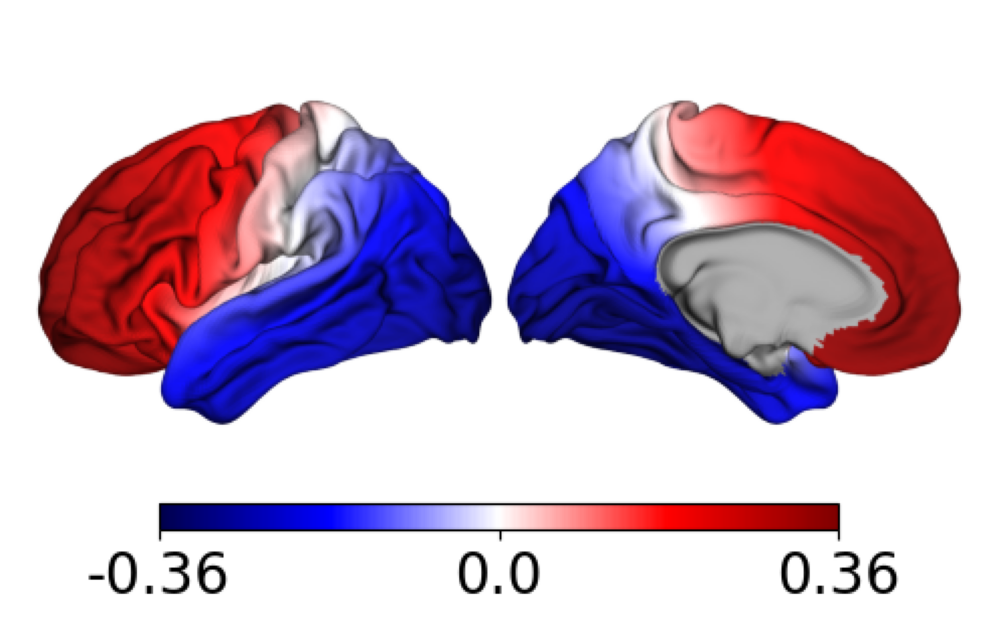

In [83]:
fig, axs = plt.subplots(1, 1, figsize=(16, 8))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, solver.unmask_data(recon_mode_map), cmap='seismic', center=0, cbar=True, ax=axs)